# 3. Parametric string method and minimum-energy paths

This keeps the `String2D` workflow from the uploaded code. The default example is
a known **synthetic double well**. Changing initial/mid/final x ordering is allowed.

The bundled implementation fixes the `xy` gradient-axis ordering, avoids division
by zero on flat surfaces, and checks both images and connecting segments against
finite grid support. It warns when the numerical string does not converge.
The unmodified supplied implementation is retained under `reference/`.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from bivo4_fes import *

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
OUT = ROOT / "results"
OUT.mkdir(exist_ok=True)

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
GRID_PATH = None  # FES .npz, or .dat with explicitly known energy units
GRID_ENERGY_UNIT = "kJ/mol"  # only for text data without a unit header

if GRID_PATH is None:
    print("SYNTHETIC MEP TEST -- not a BiVO4 barrier")
    x, y = np.linspace(-1.4, 1.4, 141), np.linspace(-0.5, 0.5, 101)
    X, Y = np.meshgrid(x, y, indexing="ij")
    z = (X*X - 1.0)**2 + 4.0*Y*Y
    begin, end, mid = [-1.0, 0.0], [1.0, 0.0], [[0.0, 0.15]]
else:
    path = Path(GRID_PATH)
    f = FES.load(path) if path.suffix == ".npz" else read_fes(path, energy_unit=GRID_ENERGY_UNIT)
    x, y, z = *f.axes, f.free_energy
    # REPLACE these example points with supported endpoints on YOUR FES.
    begin, end, mid = [-0.8, 2.8], [0.8, 2.8], [[0.0, 2.5]]
    # Optional: mask low-support cells before searching, after checking diagnostics.
    # z = np.where(f.local_ess >= chosen_threshold, z, np.nan)

S = String2D(x, y, z, indexing="ij", scales=(1.0, 1.0))
S.compute_mep(begin, end, mid=mid, npts=35, dt=0.005, maxsteps=2000,
              tol=1e-5, flexible=False, progress=False)
print("Numerically converged:", S.converged)
print("Iterations:", len(S.convergence_history))
print("Final RMS displacement:", S.convergence_history[-1])
print("Normal-gradient diagnostic:", S.normal_force_history[-1])

SYNTHETIC MEP TEST -- not a BiVO4 barrier
Numerically converged: True
Iterations: 216
Final RMS displacement: 9.896282768663437e-06
Normal-gradient diagnostic: 0.00299349319415509


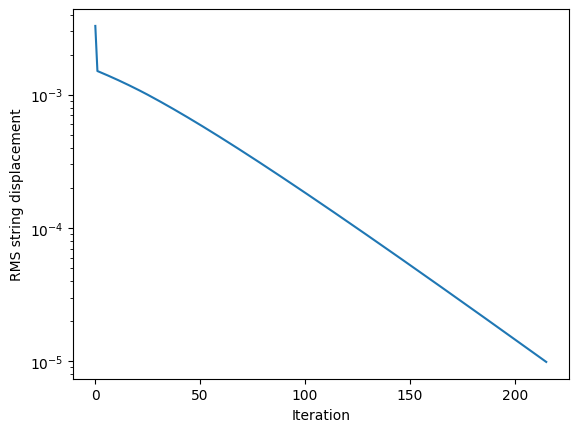

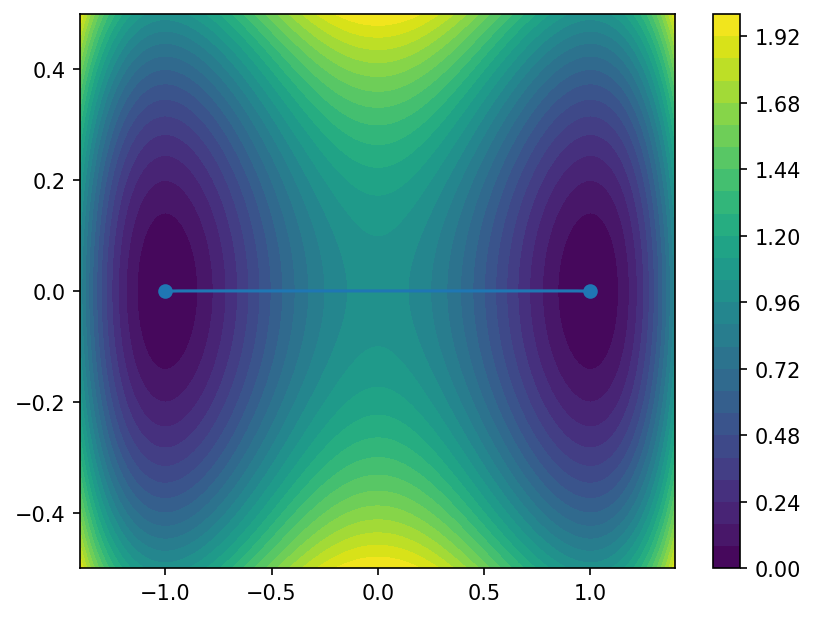

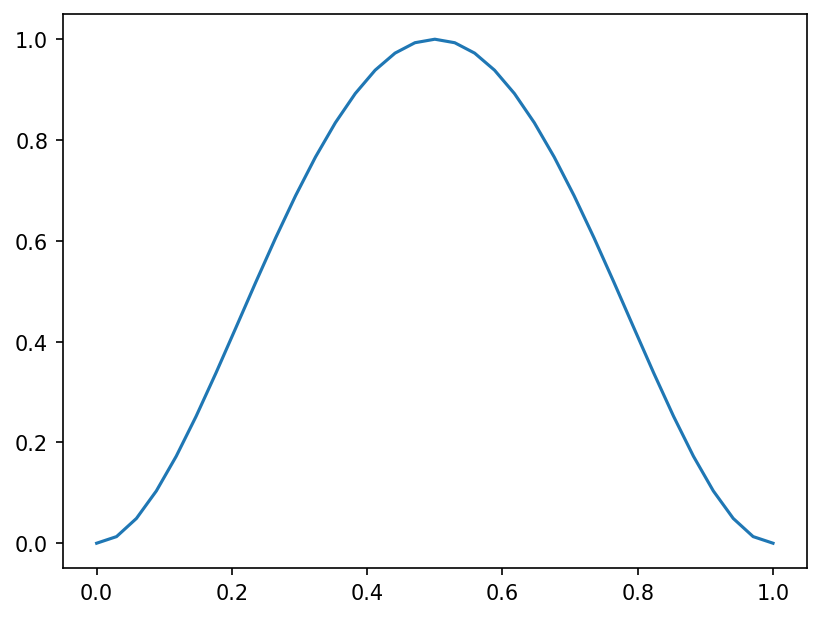

In [3]:
fig, ax = plt.subplots()
ax.semilogy(np.maximum(S.convergence_history, 1e-16))
ax.set(xlabel="Iteration", ylabel="RMS string displacement")
plt.show()
S.plot_mep(levels=25)
plt.show()
S.plot_mep_energy_profile()
plt.show()

In [4]:
if S.converged:
    mep, energy = S.get_mep_energy_profile()
    print("Path maximum minus initial-point free energy:", energy.max() - energy[0])
    print("Endpoint free-energy difference:", energy[-1] - energy[0])
    np.savez_compressed(OUT / "mep.npz", path=mep, energy=energy,
                        rms=S.convergence_history, normal_gradient=S.normal_force_history)
else:
    print("Do not report a converged barrier from this path. Inspect dt and the FES.")

Path maximum minus initial-point free energy: 1.000022018201198
Endpoint free-energy difference: -9.060308059361022e-18


## Automatic grid initialization (optional)

The minimax initializer searches for a supported grid route with the smallest
maximum free energy, using path length as a tie-breaking heuristic. It snaps
endpoints to grid points, returned explicitly. It is an initializer, not an MFEP.

The same physical CV metric must be used throughout. For mixed-unit CVs, raw
Euclidean distance is a convention, not a unique physical metric. The string
search is local and can converge to different channels.

Grid-snapped endpoints: [[-1.  0.]
 [ 1.  0.]]
Auto-initialized numerical convergence: True


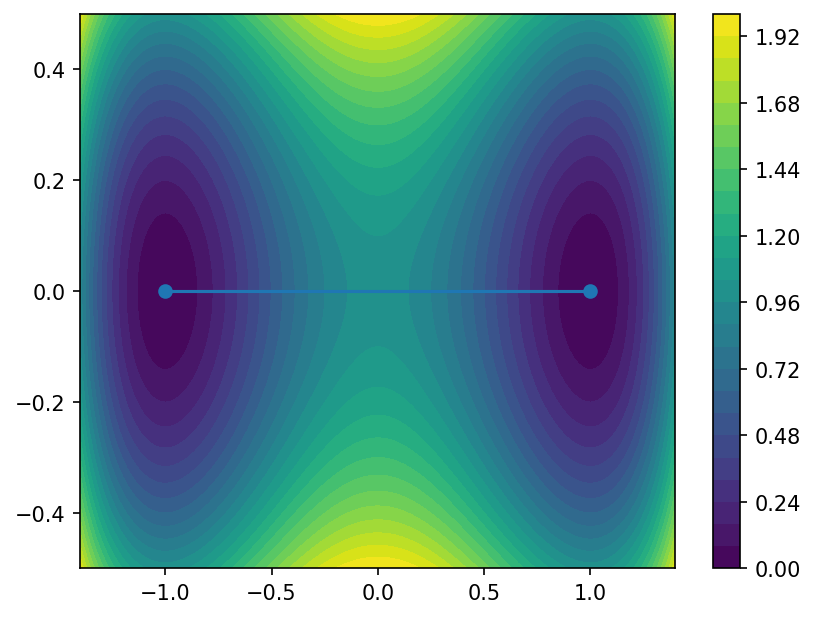

In [5]:
route = minimax_path(x, y, z, begin, end)
print("Grid-snapped endpoints:", route[[0, -1]])
S_auto = String2D(x, y, z, indexing="ij")
S_auto.compute_mep(route[0], route[-1], initial_path=route,
                   npts=35, dt=0.005, maxsteps=2000, flexible=False, progress=False)
print("Auto-initialized numerical convergence:", S_auto.converged)
S_auto.plot_mep(levels=25)
plt.show()

## Before reporting a physical barrier

Check smaller steps, more path images, KDE bandwidth/grid resolution, finite
sampling support, and within-run block convergence. Inspect the path on the
*unclipped* FES. The numerical convergence flag says nothing by itself about
sampling convergence, MLP accuracy, or whether these CVs locate a true dynamical
transition state. For reaction free energy, `basin_delta_f` integrates state
probabilities; an endpoint-minimum difference is a different quantity.